In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [1]:
import numpy as np
import seaborn as sns
import tensorflow as tf
import matplotlib.pyplot as plt

import os
from distutils.dir_util import copy_tree, remove_tree

from PIL import Image
from random import randint

from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

import tensorflow_addons as tfa
from keras.utils.vis_utils import plot_model
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.layers import Conv2D, Flatten
from tensorflow.keras.preprocessing.image import ImageDataGenerator as IDG
from tensorflow.keras.layers import SeparableConv2D, BatchNormalization, MaxPool2D



print("TensorFlow Version:", tf.__version__)

CLASSES = [ 'NonDemented',
            'VeryMildDemented',
            'MildDemented',
            'ModerateDemented']

IMG_SIZE = 176
IMAGE_SIZE = [176, 176]
DIM = (IMG_SIZE, IMG_SIZE)

TensorFlow Version: 2.4.1


In [2]:
train_data=np.load('../input/traindata/train__data .npy')
test_data=np.load('../input/testdata/test__data .npy')
test_labels=np.load('../input/labels/Testlabels.npy')
train_labels=np.load('../input/labels/Trainlabels.npy')
val_data=np.load('../input/valdata/val__data .npy')
val_labels=np.load('../input/labels/Vallabels.npy')

In [3]:
def conv_block(filters, act='relu'):
    
    
    block = Sequential()
    block.add(Conv2D(filters, 3, activation=act, padding='same'))
    block.add(Conv2D(filters, 3, activation=act, padding='same'))
    block.add(BatchNormalization())
    block.add(MaxPool2D())
    
    return block

In [4]:
def dense_block(units, dropout_rate, act='relu'):
    
    
    block = Sequential()
    block.add(Dense(units, activation=act))
    block.add(BatchNormalization())
    block.add(Dropout(dropout_rate))
    
    return block

In [5]:
def construct_model(act='relu'):
    
    
    model = Sequential([
        Input(shape=(*IMAGE_SIZE, 3)),
        Conv2D(16, 3, activation=act, padding='same'),
        Conv2D(16, 3, activation=act, padding='same'),
        MaxPool2D(),
        conv_block(32),
        conv_block(64),
        conv_block(128),
        Dropout(0.2),
        conv_block(256),
        Dropout(0.2),
        Flatten(),
        dense_block(512, 0.7),
        dense_block(128, 0.5),
        dense_block(64, 0.3),
        Dense(4, activation='softmax')        
    ], name = "cnn_model")

    return model

In [6]:
from keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=10)


model = construct_model()

METRICS = [tf.keras.metrics.CategoricalAccuracy(name='acc'),
           tf.keras.metrics.AUC(name='auc'), 
           tfa.metrics.F1Score(num_classes=4)]


    
model.compile(optimizer='adam',
              loss=tf.losses.CategoricalCrossentropy(),
              metrics=METRICS)

model.summary()

Model: "cnn_model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d (Conv2D)              (None, 176, 176, 16)      448       
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 176, 176, 16)      2320      
_________________________________________________________________
max_pooling2d (MaxPooling2D) (None, 88, 88, 16)        0         
_________________________________________________________________
sequential (Sequential)      (None, 44, 44, 32)        14016     
_________________________________________________________________
sequential_1 (Sequential)    (None, 22, 22, 64)        55680     
_________________________________________________________________
sequential_2 (Sequential)    (None, 11, 11, 128)       221952    
_________________________________________________________________
dropout (Dropout)            (None, 11, 11, 128)       0 

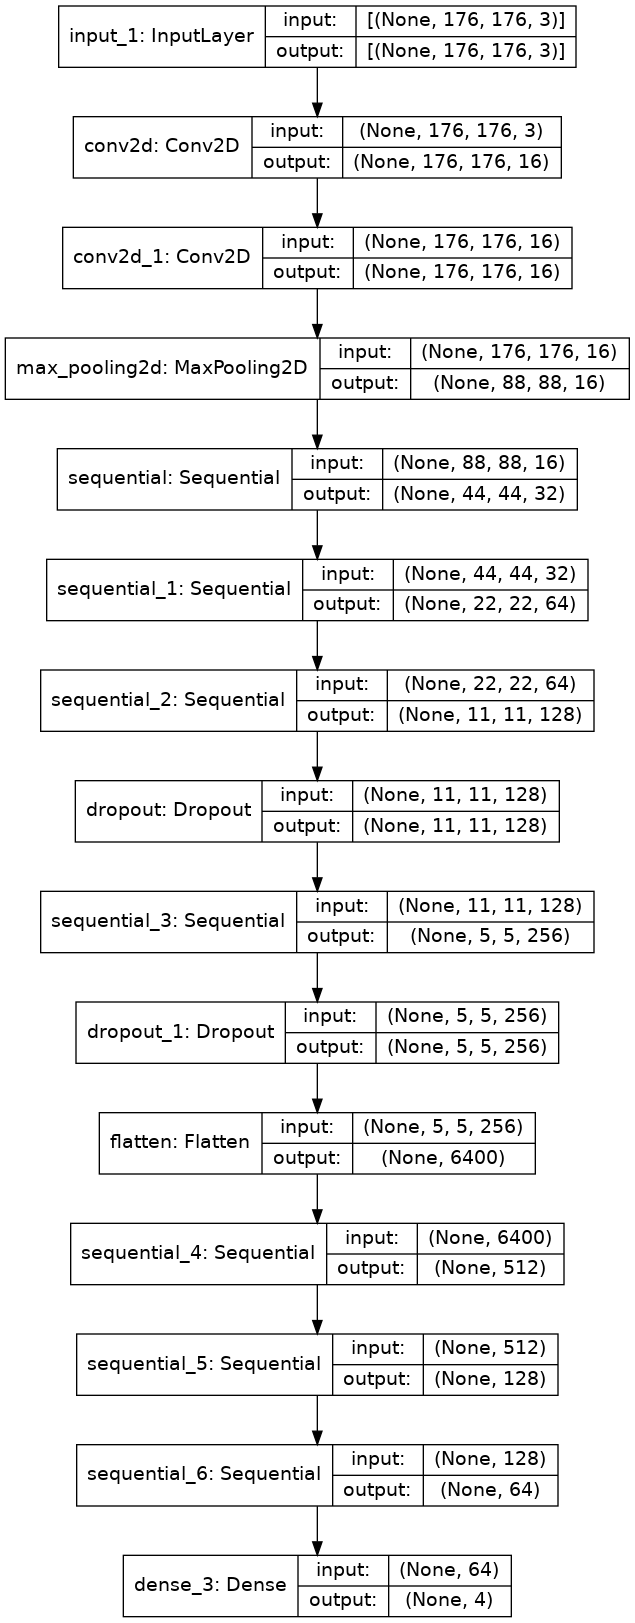

In [7]:
import IPython
import keras

keras.utils.plot_model(model, to_file='test_keras_plot_model.png', show_shapes=True)
IPython.display.Image('test_keras_plot_model.png')

In [8]:
EPOCHS = 55
history = model.fit(train_data, train_labels, validation_data=(val_data, val_labels),  callbacks=[early_stopping], epochs=EPOCHS)

Epoch 1/55
256/256 [==============================] - 54s 182ms/step - loss: 1.9104 - acc: 0.2797 - auc: 0.5273 - f1_score: 0.2804 - val_loss: 3.9881 - val_acc: 0.2607 - val_auc: 0.4748 - val_f1_score: 0.1034
Epoch 2/55
256/256 [==============================] - 45s 176ms/step - loss: 1.4748 - acc: 0.3146 - auc: 0.5784 - f1_score: 0.3117 - val_loss: 2.5105 - val_acc: 0.2764 - val_auc: 0.5184 - val_f1_score: 0.1785
Epoch 3/55
256/256 [==============================] - 45s 176ms/step - loss: 1.0857 - acc: 0.5011 - auc: 0.7793 - f1_score: 0.4940 - val_loss: 1.8686 - val_acc: 0.3423 - val_auc: 0.6123 - val_f1_score: 0.2741
Epoch 4/55
256/256 [==============================] - 45s 176ms/step - loss: 0.8128 - acc: 0.6234 - auc: 0.8770 - f1_score: 0.6133 - val_loss: 1.1302 - val_acc: 0.4697 - val_auc: 0.7572 - val_f1_score: 0.4453
Epoch 5/55
256/256 [==============================] - 45s 176ms/step - loss: 0.7366 - acc: 0.6619 - auc: 0.8998 - f1_score: 0.6569 - val_loss: 7.0745 - val_acc: 0.2

In [9]:
model.save('detectionmodel.h5')

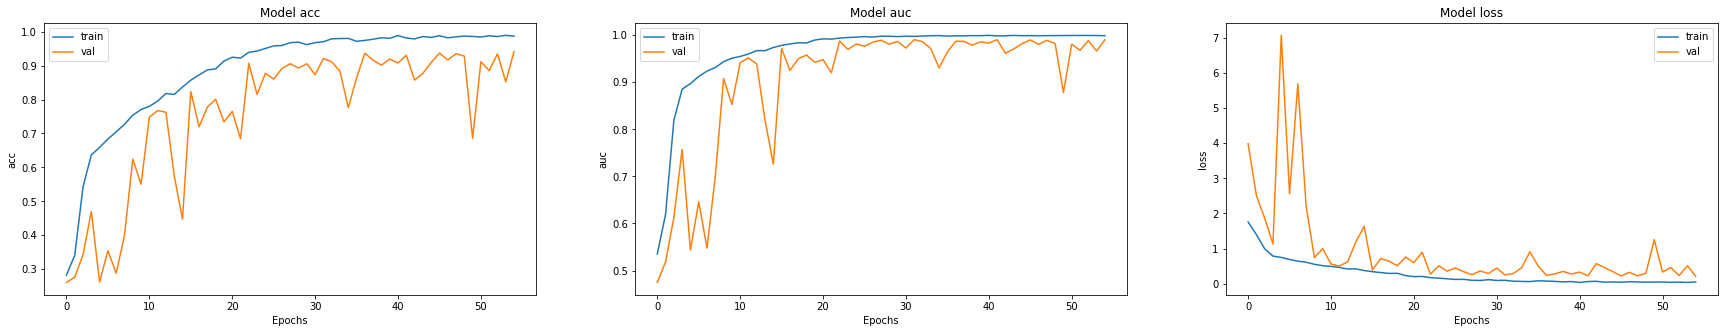

In [10]:
fig, ax = plt.subplots(1, 3, figsize = (30, 5))
ax = ax.ravel()

for i, metric in enumerate(["acc", "auc", "loss"]):
    ax[i].plot(history.history[metric])
    ax[i].plot(history.history["val_" + metric])
    ax[i].set_title("Model {}".format(metric))
    ax[i].set_xlabel("Epochs")
    ax[i].set_ylabel(metric)
    ax[i].legend(["train", "val"])